** Extraction of individual prosumers from SimBench and DWD Dataset to add to Bus33 System **

Simbench provides a number of standalone profiles for PV, HP, EV etc. - but not a full prosumer profile that is linked to exactly one node in the graph (the nodes model a consumer and the lines are modeled through resistances/thermal limits); a node in SimBench is aggregated, meaning if we have a node labeled H0-A that just means “this node has residential load with H0-A shape”

Goal of the Notebook: illustrate the different types of prosumer profiles that should be modeled by "scenarios.py" and added to nodes in (1) the Bus33 System and (2) the Simbench LV System

In [15]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
# ── Profile statistics table ──────────────────────────────────────────────────
def profile_stats(df, profile_type):
    """Compute annual statistics for all p-load profiles in a DataFrame."""
    cols = [c for c in df.columns if 'pload' in c or c in df.columns
            and not 'qload' in c and not 'time' in c.lower()]
    # For RESProfile, all columns are generation
    rows = []
    for col in df.columns:
        if 'time' in col.lower(): continue
        vals = df[col].values
        rows.append({
            'Profile':      col,
            'Type':         profile_type,
            'Annual mean':  round(vals.mean(), 4),
            'Annual max':   round(vals.max(), 4),
            'Annual min':   round(vals.min(), 4),
            'Winter mean':  round(vals[10*96:40*96].mean(), 4),   # Jan
            'Summer mean':  round(vals[180*96:210*96].mean(), 4), # Jul
            'Summer/Winter ratio': round(
                vals[180*96:210*96].mean() /
                max(vals[10*96:40*96].mean(), 1e-9), 3),
            'Seasonality':  round(abs(vals[180*96:210*96].mean() -
                                      vals[10*96:40*96].mean()), 4),
        })
    return pd.DataFrame(rows)

# Load profiles
path_lp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/LoadProfile.csv'
path_rp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/RESProfile.csv'
lp = pd.read_csv(path_lp, sep=';', index_col=0)
rp = pd.read_csv(path_rp, sep=';', index_col=0)

# Separate profile groups
groups = {
    'Household (H0)':     [c for c in lp.columns if c.startswith('H0') and 'pload' in c],
    'Commercial (G)':     [c for c in lp.columns if c.startswith('G')  and 'pload' in c],
    'Agricultural (L)':   [c for c in lp.columns if c.startswith('L')  and 'pload' in c],
    'HP — Hanover':       [c for c in lp.columns if ('Air' in c or 'Soil' in c)
                           and '_1_pload' in c],
    'HP — Lübeck':        [c for c in lp.columns if ('Air' in c or 'Soil' in c)
                           and '_2_pload' in c],
    'EV home (HLS)':      [c for c in lp.columns if 'HLS' in c and 'pload' in c],
    'EV workplace (APLS)': [c for c in lp.columns if 'APLS' in c and 'pload' in c
                            and '_0.' not in c],
    'PV':                 [c for c in rp.columns if c.startswith('PV')],
}

# Print stats per group
for group_name, cols in groups.items():
    print(f"\n{'='*60}")
    print(f"  {group_name}")
    print(f"{'='*60}")
    rows = []
    for col in cols:
        df = lp if col in lp.columns else rp
        vals = df[col].values
        rows.append({
            'Profile':         col.replace('_pload',''),
            'Annual mean':     round(vals.mean(), 4),
            'Max':             round(vals.max(), 4),
            'Winter mean':     round(vals[10*96:40*96].mean(), 4),
            'Summer mean':     round(vals[180*96:210*96].mean(), 4),
            'S/W ratio':       round(vals[180*96:210*96].mean() /
                                     max(vals[10*96:40*96].mean(),1e-9), 2),
            'Peak hour (avg)': int(vals.reshape(-1,96).mean(axis=0).argmax() / 4),
        })
    print(pd.DataFrame(rows).set_index('Profile').to_string())


  Household (H0)
         Annual mean  Max  Winter mean  Summer mean  S/W ratio  Peak hour (avg)
Profile                                                                        
H0-A          0.1391  1.0       0.2598       0.0480       0.18                9
H0-B          0.0883  1.0       0.1093       0.0876       0.80               12
H0-C          0.1174  1.0       0.1488       0.0891       0.60               21
H0-G          0.0696  1.0       0.0916       0.0362       0.40               18
H0-H          0.6617  1.0       0.6619       0.6588       1.00               18
H0-L          0.0565  1.0       0.0574       0.0500       0.87               18

  Commercial (G)
         Annual mean  Max  Winter mean  Summer mean  S/W ratio  Peak hour (avg)
Profile                                                                        
G0-A          0.3468  1.0       0.3193       0.4074       1.28                9
G0-M          0.3906  1.0       0.3918       0.4329       1.11               10
G1-A

HOUSEHOLD DIFFERENCES
Outlier H0-H with 0.6617 annual mean 

COMMERCIAL DIFFERENCES
G3-H either outlier or much larger company than rest 

HP DIFFERENCES
different types of HP - note functional differences, not relevant for allocation 

EV WORKPLACE DIFFERENCES
APLS_A_22.0       0.0014  0.9829       0.0001       0.0013      10.05                5
--> strangely high S/W ratio; leave out 

PV DIFFERENCES
PV1, PV2: peak at 9h → east-facing
PV3, PV4, PV5, PV6: peak at 11–12h → south-facing
PV7: peak at 14h → west-facing
--> potentially relevant for allocation 

NOTE: don't mix and match between cities as it makes the analysis in terms of temp./coherence difficult!

In [17]:
# set paths, import prosumer scenario data 
path_lp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/LoadProfile.csv'
path_rp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/RESProfile.csv'
lp = pd.read_csv(path_lp, sep=';', index_col=0)
rp = pd.read_csv(path_rp, sep=';', index_col=0)

# Import type definitions from scenarios.py
from scenarios import PROSUMER_TYPES, DEMAND_PROFILES, HP_PROFILES, PV_PROFILES

In [18]:
# ── Summary table ─────────────────────────────────────────────────────────────
rows = []
for tid, cfg in PROSUMER_TYPES.items():
    dp = DEMAND_PROFILES[cfg['demand_profile']]
    rows.append({
        'Type': f"T{tid}",
        'Name': cfg['name'],
        'Demand profile': cfg['demand_profile'],
        'Demand sector': dp['sector'],
        'Peak demand kW': dp['peak_kw'],
        'PV profile': cfg['pv_profile'] or '—',
        'PV kWp': cfg['pv_capacity_kwp'],
        'BESS kWh': cfg['bess_kwh'],
        'BESS kW': cfg['bess_kw'],
        'HP': '✓' if cfg['has_hp'] else '—',
        'HP kW': cfg['hp_rated_kw'] if cfg['has_hp'] else '—',
        'EV profile': cfg['ev_profile'] or '—',
        'EV kWh': cfg['ev_capacity_kwh'] or '—',
    })

summary = pd.DataFrame(rows).set_index('Type')
display(summary)

,Name,Demand profile,Demand sector,Peak demand kW,PV profile,PV kWp,BESS kWh,BESS kW,HP,HP kW,EV profile,EV kWh
Type,,,,,,,,,,,,
T1,Residential ++,H0-B,residential,8,PV5,12.0,15.0,7.0,✓,10.0,HLS_A_11.0,60.0
T2,Residential --,H0-C,residential,7,—,0.0,0.0,0.0,—,—,HLS_B_3.7,40.0
T3,Residential PV only,H0-A,residential,6,PV7,8.0,10.0,5.0,—,—,—,—
T4,Residential HP only,H0-G,residential,5,—,0.0,0.0,0.0,✓,8.0,—,—
T5,Restaurant,G3-A,commercial,20,PV4,15.0,10.0,5.0,—,—,—,—
T6,Office building,G4-B,commercial,25,PV1,30.0,20.0,10.0,—,—,APLS_A_11.0,40.0
T7,School,G4-A,commercial,30,PV5,40.0,30.0,15.0,—,—,—,—
T8,Day-round facility,G2-A,commercial,20,PV3,10.0,25.0,12.0,—,—,—,—
T9,Agricultural farm,L1-A,agricultural,25,PV6,50.0,50.0,20.0,—,—,—,—


In [19]:
# plotting setup (add season splits, plot types/colours/functions)
SEASONS = {
    'winter': slice(14*96,  15*96),
    'spring': slice((31+29+31+14)*96,         (31+29+31+15)*96),
    'summer': slice((31+29+31+30+31+30+14)*96, (31+29+31+30+31+30+15)*96),
    'autumn': slice((31+29+31+30+31+30+31+31+30+14)*96,
                    (31+29+31+30+31+30+31+31+30+15)*96),
}
SEASON_COLORS = {'winter':'#6B4C9A','spring':'#2E6F52',
                 'summer':'#F0C040','autumn':'#B5720A'}
t = np.arange(96) * 0.25   # hours 0–24

plt.rcParams.update({'font.size':9,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42})

def plot_type(type_id):
    cfg  = PROSUMER_TYPES[type_id]
    dp   = DEMAND_PROFILES[cfg['demand_profile']]
    
    # Count active panels
    panels = ['Demand']
    if cfg['pv_profile']:             panels.append('PV')
    if cfg['has_hp']:                 panels.append('HP')
    if cfg.get('ev_profile'):         panels.append('EV')
    
    fig, axes = plt.subplots(1, len(panels), figsize=(5*len(panels), 4.5))
    if len(panels) == 1: axes = [axes]
    
    ax_idx = 0
    
    # ── Demand ───────────────────────────────────────────────────────────────
    ax = axes[ax_idx]; ax_idx += 1
    for season, slc in SEASONS.items():
        vals = lp[cfg['demand_profile']+'_pload'].values[slc] * dp['peak_kw']
        ax.plot(t, vals, color=SEASON_COLORS[season], lw=2.0, label=season)
    ax.set_title(f"Demand\n{cfg['demand_profile']} × {dp['peak_kw']} kW",
                 fontweight='bold')
    ax.set_xlabel('Hour'); ax.set_ylabel('kW')
    ax.set_xlim(0,24); ax.legend(fontsize=7)
    ax.text(0.5, -0.18, dp['label'], transform=ax.transAxes,
            ha='center', fontsize=7.5, color='#555555', style='italic')
    
    # ── PV ───────────────────────────────────────────────────────────────────
    if cfg['pv_profile']:
        ax = axes[ax_idx]; ax_idx += 1
        pv_info = PV_PROFILES[cfg['pv_profile']]
        for season, slc in SEASONS.items():
            vals = rp[cfg['pv_profile']].values[slc] * cfg['pv_capacity_kwp']
            ax.plot(t, vals, color=SEASON_COLORS[season], lw=2.0, label=season)
        ax.set_title(f"PV Generation\n{cfg['pv_profile']} × {cfg['pv_capacity_kwp']} kWp",
                     fontweight='bold')
        ax.set_xlabel('Hour'); ax.set_ylabel('kW')
        ax.set_xlim(0,24); ax.legend(fontsize=7)
        ax.text(0.5, -0.18, f"{pv_info[0]}-facing · {pv_info[1]} · {pv_info[2]}",
                transform=ax.transAxes, ha='center', fontsize=7.5,
                color='#555555', style='italic')
    
    # ── HP ───────────────────────────────────────────────────────────────────
    if cfg['has_hp']:
        ax = axes[ax_idx]; ax_idx += 1
        # Show all HP profile types for context
        hp_cols = [c for c in lp.columns if 'pload' in c and
                   ('Air' in c or 'Soil' in c)]
        colors_hp = ['#2F6FA3','#C65D3B','#2E6F52','#6B4C9A',
                     '#B5720A','#444444','#888888','#AA3377']
        for season in ['winter','summer']:
            slc = SEASONS[season]
            for j, col in enumerate(hp_cols[:4]):   # Hanover profiles only
                vals = lp[col].values[slc] * cfg['hp_rated_kw']
                ls = '-' if season == 'winter' else '--'
                ax.plot(t, vals, color=colors_hp[j], lw=1.5, ls=ls,
                        label=f"{col.replace('_pload','').replace('_1','')} {'W' if season=='winter' else 'S'}")
        ax.set_title(f"HP (random from pool)\nRated {cfg['hp_rated_kw']} kW",
                     fontweight='bold')
        ax.set_xlabel('Hour'); ax.set_ylabel('kW')
        ax.set_xlim(0,24)
        ax.legend(fontsize=6, ncol=2)
        ax.text(0.5, -0.18, 'Solid=winter · Dashed=summer · colour=HP type',
                transform=ax.transAxes, ha='center', fontsize=7.5,
                color='#555555', style='italic')
    
    # ── EV ───────────────────────────────────────────────────────────────────
    if cfg.get('ev_profile'):
        ax = axes[ax_idx]; ax_idx += 1
        ev_col = cfg['ev_profile'] + '_pload'
        ev_kw  = float(cfg['ev_profile'].split('_')[2])
        for season, slc in SEASONS.items():
            vals = lp[ev_col].values[slc] * ev_kw
            ax.plot(t, vals, color=SEASON_COLORS[season], lw=2.0, label=season)
        ev_type_label = 'Home charging (HLS)' if 'HLS' in cfg['ev_profile'] \
                        else 'Workplace charging (APLS)'
        ax.set_title(f"EV Charging\n{cfg['ev_profile']} · {cfg['ev_capacity_kwh']} kWh",
                     fontweight='bold')
        ax.set_xlabel('Hour'); ax.set_ylabel('kW')
        ax.set_xlim(0,24); ax.legend(fontsize=7)
        ax.text(0.5, -0.18, ev_type_label, transform=ax.transAxes,
                ha='center', fontsize=7.5, color='#555555', style='italic')
    
    # BESS annotation in title
    bess_str = (f"BESS: {cfg['bess_kwh']} kWh / {cfg['bess_kw']} kW"
                if cfg['bess_kwh'] > 0 else "No BESS")
    fig.suptitle(f"Type {type_id}: {cfg['name']}  ·  {cfg['description']}\n{bess_str}",
                 fontweight='bold', fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()

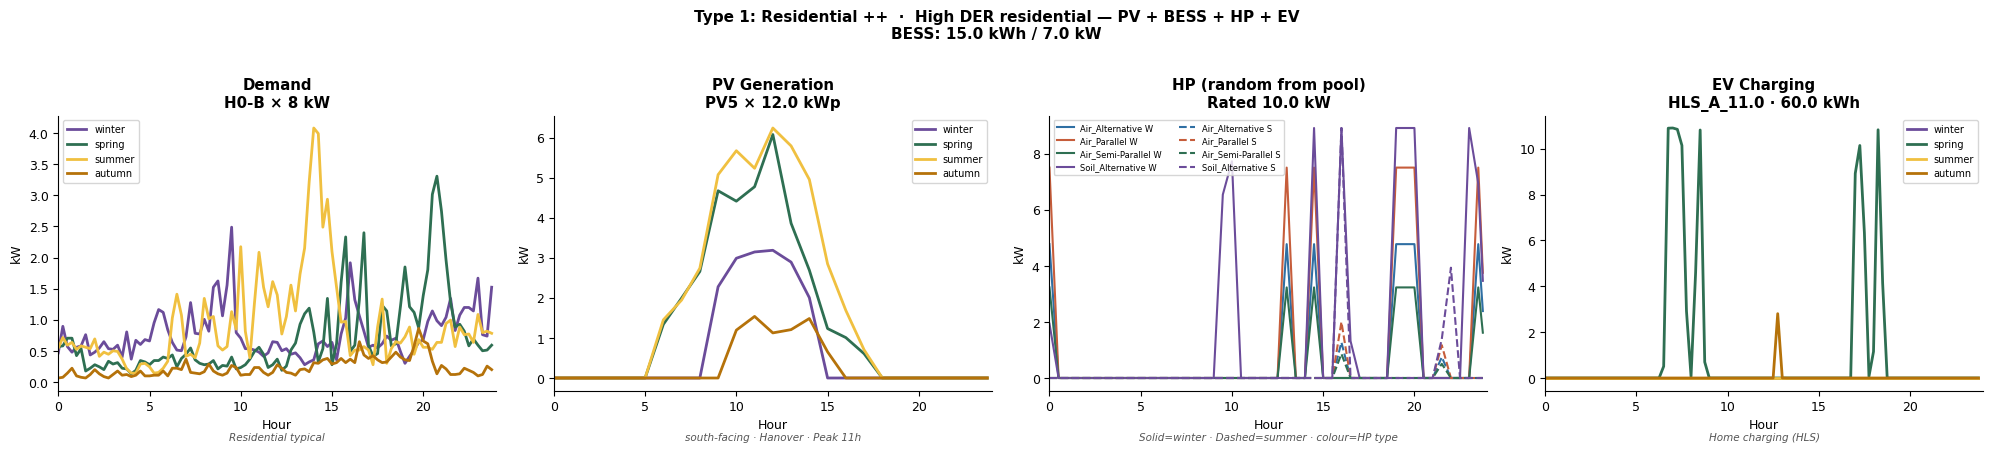

In [20]:
# type 1: residential prosumer, ++ renewable energy
plot_type(1)

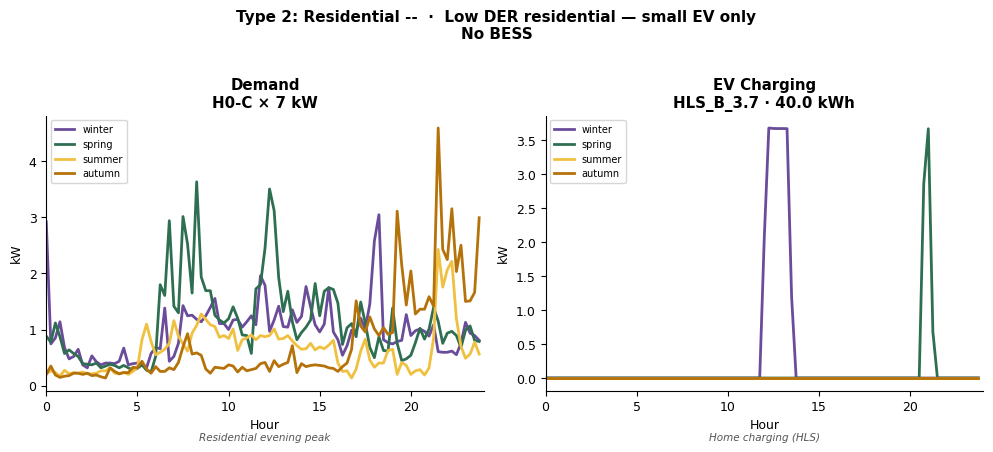

In [21]:
# type 2: residential prosumer, -- renewable energy
plot_type(2)

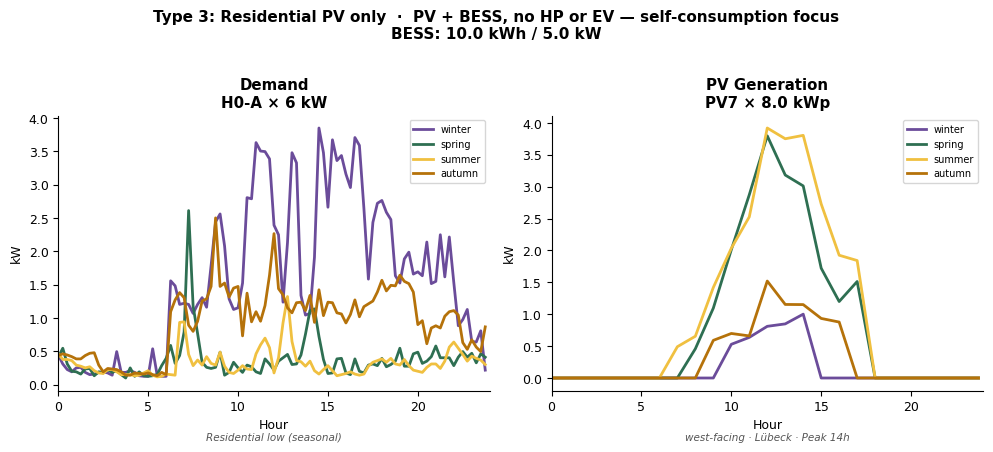

In [22]:
# type 3: residential prosumer, PV only 
plot_type(3)

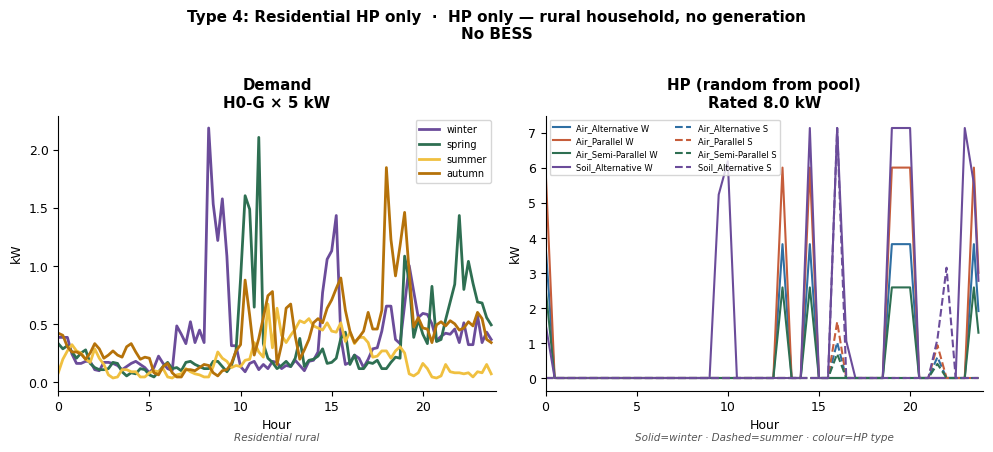

In [23]:
# type 4: residential prosumer, HP only 
plot_type(4)

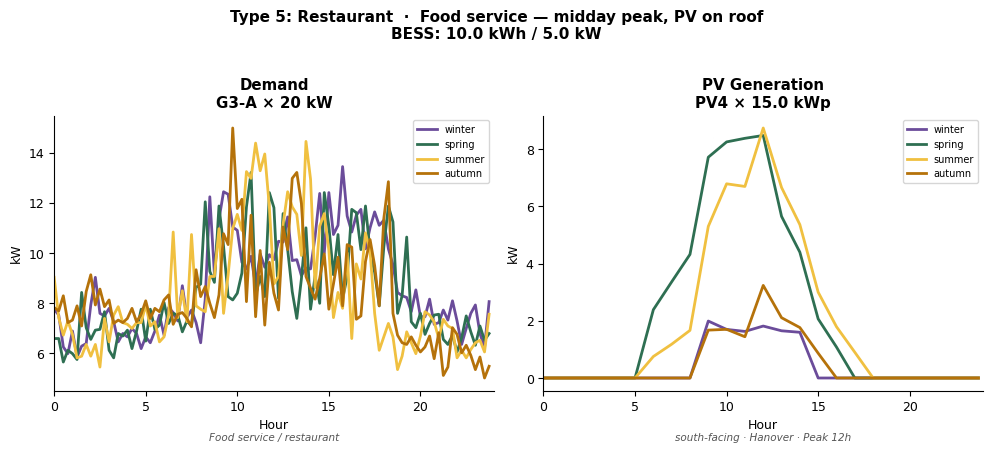

In [24]:
# type 5: restaurant
plot_type(5)

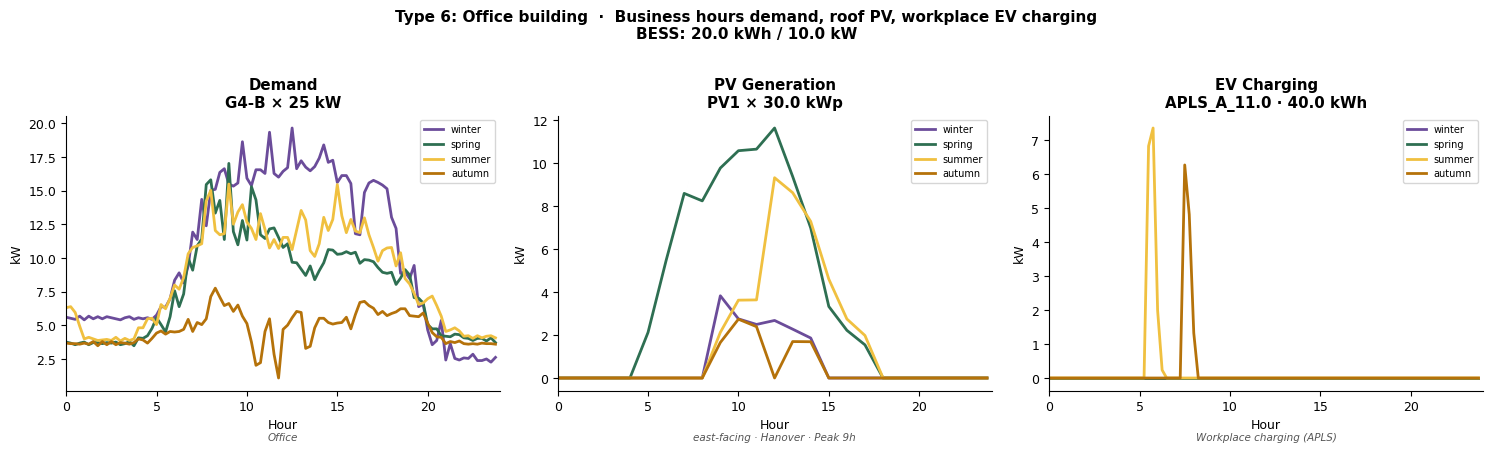

In [25]:
# type 6: office building
plot_type(6)

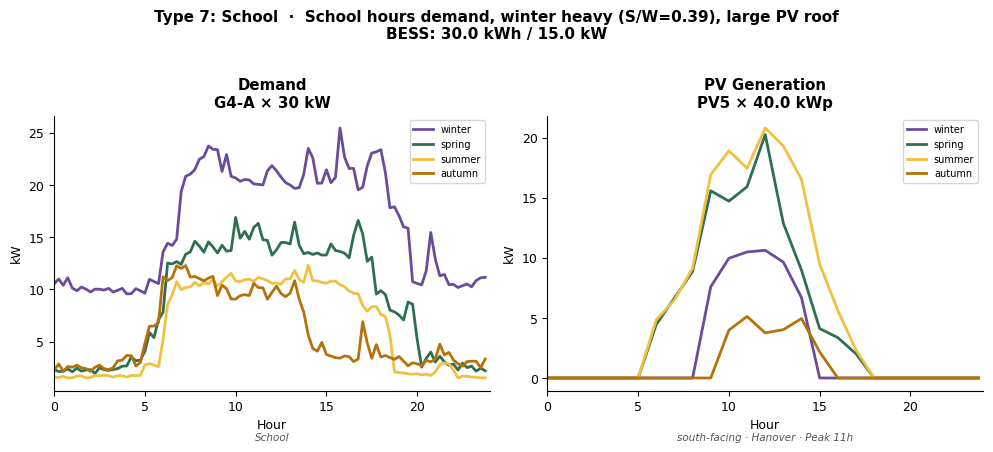

In [26]:
# type 7: school 
plot_type(7)

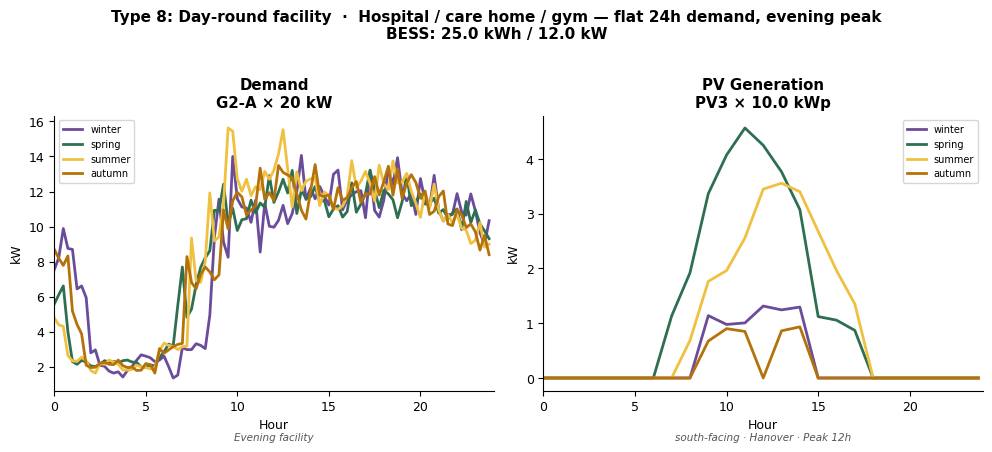

In [27]:
# type 8: day-round facility 
plot_type(8)

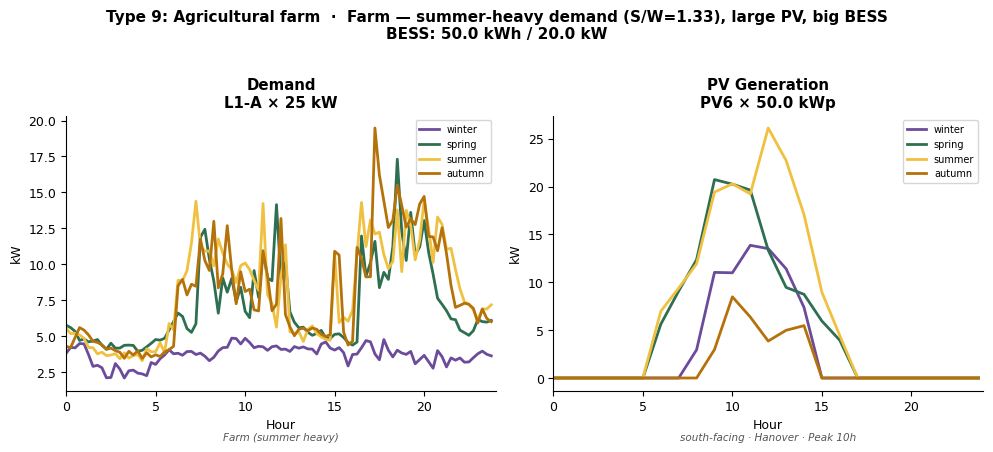

In [29]:
# type 9: agricultural farm
plot_type(9)

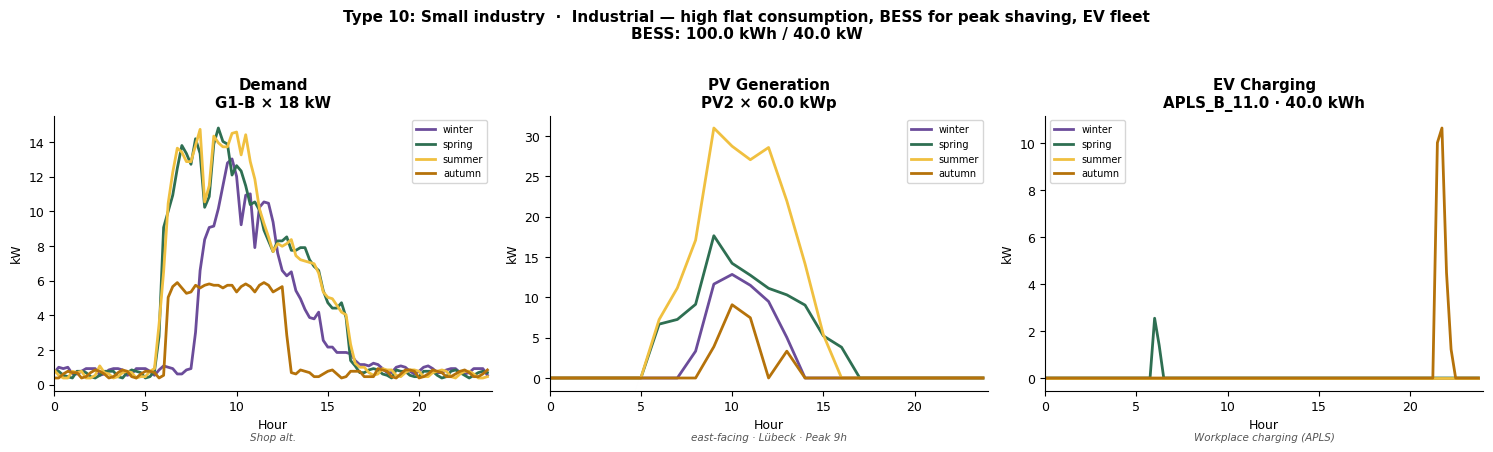

In [28]:
# type 10: small industry
plot_type(10)